# H3: Frozen Deep Feature Fusion for Lung Histopathology

**Experiment:** `H3_MobileNetV2_EfficientNetB0_fusion_seed42`  
**Input:** RGB LC25000 lung images, resized with padding to 224 × 224  
**Classes:** `lung_aca`, `lung_n`, `lung_scc`  
**Split:** fixed reconstructed source-image-group manifest (not patient-separated)  
**Evaluation scope:** **validation only; no held-out test image is extracted, decoded, predicted, or used for model selection**.

This experiment performs **feature-level fusion**, not prediction averaging. It loads the previously saved H1 MobileNetV2 and H2 EfficientNetB0 checkpoints, retains their frozen ImageNet-trained feature extractors, takes their 1,280-dimensional global-average-pooled representations, concatenates them into 2,560 dimensions, and trains a new `Dropout(0.2) → Dense(3, softmax)` head (7,683 trainable parameters). The H1/H2 classification heads are **not** used in fusion.

The two reference backbones were frozen during H1/H2 training; this fusion experiment does not claim their backbone weights were fine-tuned for lung images. There is **no stain normalization, stain-aware augmentation, robustness evaluation, or Grad-CAM in H3**. Those are separate approved-method experiments. This work is not clinical diagnosis.

**Execution:** Run Sections 1–10 **in order, one code cell at a time**. Confirm each output before proceeding. Section 6 may create a reusable feature cache after explicit confirmation; Section 8 alone fits the H3 classification head after `TRAIN H3` authorization. Do not use `Run all`.


## Experiment boundaries and storage

| Split | Images | Reconstructed source-image groups | Usage |
|---|---:|---:|---|
| Train | 10,394 | 514 | Feature extraction and H3-head fitting |
| Validation | 2,273 | 113 | Feature extraction, best-checkpoint selection, comparison |
| Held-out test | 2,333 | 113 | **Not loaded or evaluated in this notebook** |

The source manifest, three-class mapping, archive, original H1/H2 result folders, and audit remain unchanged. H3 results go to a **new** Drive directory under `lung/results/`; cached features go to a separate fingerprinted `lung/feature_cache/` directory. Feature cache files are derived from train/validation images only, checked against the saved manifest order, and excluded from the portable evidence ZIP. A full input-image-to-prediction fusion model is exported in Section 10 for reproducibility.

For H1/H2 comparison, the same class order, group split, resize settings, and model-selection rule are retained. Because fusion uses two extractors, its architecture and training budget remain a different model; any validation gain must be described as an observed comparison, not guaranteed superiority.


## 1. Drive sources and previous baseline records

Mount Drive and find the saved LC25000 source files **and the completed H1/H2 checkpoints**. Read their experiment records; do not download archives, edit manifests, or initiate training.


In [ ]:
# Read existing sources and locate the completed H1/H2 evidence; no training.
from google.colab import drive
from pathlib import Path, PurePosixPath
from IPython.display import display
import hashlib
import json
import pandas as pd

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/ICTIU_Final_Projects')
LUNG = ROOT / 'lung'
SOURCE_FILES = {
    'archive': LUNG / 'archives/LC25000.zip',
    'manifest': LUNG / 'splits/manifest_candidate.csv',
    'mapping': LUNG / 'splits/class_mapping.json',
    'groups': LUNG / 'metadata/lc25000_image_groups.csv',
    'audit': LUNG / 'results/audit.json',
}
BASELINE_DIRS = {
    'H1': LUNG / 'results/H1_MobileNetV2_frozen_seed42',
    'H2': LUNG / 'results/H2_EfficientNetB0_frozen_seed42',
}
BASELINE_REQUIRED = (
    'best_model.keras', 'configuration.json', 'training_status.json',
    'validation_metrics.json',
)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(4 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def read_json(path):
    with Path(path).open(encoding='utf-8-sig') as handle:
        return json.load(handle)

for role, path in SOURCE_FILES.items():
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'Missing {role}: {path}')
    print(f'OK: {path.relative_to(LUNG)} ({path.stat().st_size / 1024**2:,.2f} MiB)')
for code, folder in BASELINE_DIRS.items():
    for name in BASELINE_REQUIRED:
        path = folder / name
        if not path.is_file() or path.stat().st_size == 0:
            raise FileNotFoundError(f'Missing saved {code} evidence: {path}')
    print(f'OK: {code} checkpoint and saved validation records: {folder.name}')

raw_manifest = pd.read_csv(SOURCE_FILES['manifest'], dtype=str, keep_default_na=False)
raw_mapping = read_json(SOURCE_FILES['mapping'])
saved_audit = read_json(SOURCE_FILES['audit'])
SOURCE_SHA256 = {
    role: sha256_file(path) for role, path in SOURCE_FILES.items() if role != 'archive'
}
EXPECTED_MANIFEST_SHA256 = 'd931c9b11d03716c3c426f251bc75eaa2051002acca99d3ba66d59d964285dea'
if SOURCE_SHA256['manifest'] != EXPECTED_MANIFEST_SHA256:
    raise ValueError('Manifest differs from the verified lung H1/H2 split. Do not re-split.')
BASELINE_RECORDS = {
    code: {
        'config': read_json(folder / 'configuration.json'),
        'status': read_json(folder / 'training_status.json'),
        'metrics': read_json(folder / 'validation_metrics.json'),
    }
    for code, folder in BASELINE_DIRS.items()
}
print('\nManifest rows:', len(raw_manifest))
print('Saved class mapping:', raw_mapping)
print('Saved audit groups:', saved_audit.get('unique_groups'))
print('Original lung manifest SHA-256:', SOURCE_SHA256['manifest'])
print('Section 1 passed. Both completed baseline result folders are present.')


Mounted at /content/drive
OK: archives/LC25000.zip (1,801.84 MiB)
OK: splits/manifest_candidate.csv (2.44 MiB)
OK: splits/class_mapping.json (0.00 MiB)
OK: metadata/lc25000_image_groups.csv (1.19 MiB)
OK: results/audit.json (0.00 MiB)
OK: H1 checkpoint and saved validation records: H1_MobileNetV2_frozen_seed42
OK: H2 checkpoint and saved validation records: H2_EfficientNetB0_frozen_seed42

Manifest rows: 15000
Saved class mapping: {'lung_aca': 0, 'lung_n': 1, 'lung_scc': 2}
Saved audit groups: 740
Original lung manifest SHA-256: d931c9b11d03716c3c426f251bc75eaa2051002acca99d3ba66d59d964285dea
Section 1 passed. Both completed baseline result folders are present.


## 2. Fixed split, class mapping, and H1/H2 provenance verification

Use the same audited lung source-image groups as H1 and H2. Verify both reference checkpoints have the same manifest/class mapping and are finished **validation-only** runs. No test image pixels are read.


In [ ]:
# Validate the existing manifest; standardize column access in memory.
EXPECTED_IMAGES = {'train': 10394, 'val': 2273, 'test': 2333}
EXPECTED_GROUPS = {'train': 514, 'val': 113, 'test': 113}
EXPECTED_CLASSES = {'lung_aca', 'lung_n', 'lung_scc'}
COLUMN_OVERRIDES = {
    'path': None, 'split': None, 'class_name': None,
    'class_id': None, 'group': None, 'sha256': None,
}
ALIASES = {
    'path': ['relative_path', 'rel_path', 'relpath', 'image_path', 'filepath', 'file_path',
             'path', 'filename', 'file_name', 'image_name', 'image'],
    'split': ['split', 'subset', 'partition', 'set'],
    'class_name': ['class_name', 'class', 'category', 'label_name', 'label', 'target'],
    'class_id': ['class_id', 'label_id', 'label_idx', 'class_idx', 'target_id'],
    'group': ['group_id', 'source_group_id', 'source_group', 'source_image_group',
              'source_image_group_id', 'original_group_id', 'original_group',
              'source_image_id', 'group'],
    'sha256': ['sha256', 'file_sha256', 'image_sha256', 'sha256_hash'],
}

def choose_column(role, required=False):
    lookup = {str(c).strip().lower(): c for c in raw_manifest.columns}
    override = COLUMN_OVERRIDES[role]
    if override is not None:
        if override not in raw_manifest.columns:
            raise ValueError(f'Unknown override for {role}: {override}')
        return override
    selected = next((lookup[name] for name in ALIASES[role] if name in lookup), None)
    if required and selected is None:
        raise ValueError(f'Required manifest column could not be identified: {role}.')
    return selected

mapping = raw_mapping
if isinstance(mapping, dict) and 'class_to_id' in mapping:
    mapping = mapping['class_to_id']
elif isinstance(mapping, dict) and 'class_to_idx' in mapping:
    mapping = mapping['class_to_idx']
if not isinstance(mapping, dict):
    raise ValueError('Expected a saved class-name-to-ID dictionary.')
if set(mapping) == EXPECTED_CLASSES:
    if any(isinstance(value, bool) or str(value) not in {'0', '1', '2'} for value in mapping.values()):
        raise ValueError('Class-mapping IDs must be the integers 0, 1, 2.')
    class_to_id = {name: int(value) for name, value in mapping.items()}
elif all(str(k).isdigit() for k in mapping) and set(mapping.values()) == EXPECTED_CLASSES:
    class_to_id = {name: int(key) for key, name in mapping.items()}
else:
    raise ValueError(f'Unexpected saved class mapping: {mapping}')
if set(class_to_id.values()) != {0, 1, 2} or len(class_to_id) != 3:
    raise ValueError('Saved class IDs must be exactly 0, 1, 2, with no duplicates.')
class_names = [name for name, index in sorted(class_to_id.items(), key=lambda item: item[1])]
id_to_class = {index: name for name, index in class_to_id.items()}

COLS = {role: choose_column(role, required=role in {'path', 'split', 'group'}) for role in ALIASES}
if COLS['class_name'] is None and COLS['class_id'] is None:
    raise ValueError('No saved class-name or class-ID column was identified.')
print('Selected manifest columns:', json.dumps(COLS, indent=2))

def labels_to_ids(series):
    def convert(value):
        value = str(value).strip()
        if value in class_to_id:
            return class_to_id[value]
        if value in {'0', '1', '2', '0.0', '1.0', '2.0'}:
            return int(float(value))
        raise ValueError(f'Unexpected label in the saved manifest: {value!r}.')
    return series.map(convert).astype('int32')

label_column = COLS['class_name'] or COLS['class_id']
labels = labels_to_ids(raw_manifest[label_column])
if COLS['class_name'] and COLS['class_id']:
    if not labels.equals(labels_to_ids(raw_manifest[COLS['class_id']])):
        raise ValueError('Saved class names and saved class IDs disagree.')

split_aliases = {'train': 'train', 'training': 'train', 'val': 'val',
                 'valid': 'val', 'validation': 'val', 'test': 'test', 'testing': 'test'}
raw_splits = raw_manifest[COLS['split']].str.strip().str.lower()
splits = raw_splits.map(split_aliases)
if splits.isna().any():
    raise ValueError(f'Unrecognized split values: {raw_splits[splits.isna()].unique().tolist()}')
manifest = pd.DataFrame({
    'manifest_row': range(len(raw_manifest)),
    'source_path': raw_manifest[COLS['path']].str.strip(),
    'split': splits,
    'class_id': labels,
    'class_name': labels.map(id_to_class),
    'source_group': raw_manifest[COLS['group']].str.strip(),
})
if (manifest[['source_path', 'source_group']] == '').any().any():
    raise ValueError('The manifest contains empty paths or source groups.')
if manifest['source_path'].duplicated().any():
    raise ValueError('Duplicate image paths in the saved manifest.')
if manifest.groupby('source_group')['split'].nunique().max() != 1:
    raise ValueError('Source-group overlap detected across partitions.')
if manifest.groupby('source_group')['class_name'].nunique().max() != 1:
    raise ValueError('A source group spans multiple classes; group-ID scope is inconsistent.')
image_counts = {k: int(v) for k, v in manifest['split'].value_counts().items()}
group_counts = {k: int(v) for k, v in manifest.groupby('split')['source_group'].nunique().items()}
if image_counts != EXPECTED_IMAGES or group_counts != EXPECTED_GROUPS:
    raise ValueError(f'Split-count mismatch. Images={image_counts}; groups={group_counts}.')
if manifest['source_group'].nunique() != 740:
    raise ValueError('Expected 740 reconstructed source-image groups, not patient groups.')
if manifest['class_name'].value_counts().to_dict() != {name: 5000 for name in EXPECTED_CLASSES}:
    raise ValueError('Expected 5,000 images in each lung class.')
if (pd.crosstab(manifest['split'], manifest['class_name']) == 0).any().any():
    raise ValueError('At least one split is missing a class.')

saved_hashes_checked = COLS['sha256'] is not None
if saved_hashes_checked:
    hashes = raw_manifest[COLS['sha256']].str.strip().str.lower()
    if not hashes.str.fullmatch(r'[0-9a-f]{64}').all():
        raise ValueError('The saved SHA-256 column is incomplete or malformed.')
    manifest['recorded_sha256'] = hashes
    if manifest.groupby('recorded_sha256')['split'].nunique().max() != 1:
        raise ValueError('A saved byte-identical image hash occurs in different partitions.')
else:
    print('No saved SHA-256 column recognized; image-byte checks are limited to training and validation.')

DATA_CHECKS = {
    'image_counts': image_counts, 'source_group_counts': group_counts,
    'total_reconstructed_source_groups': 740, 'groups_spanning_splits': 0,
    'saved_all_split_sha256_checked': saved_hashes_checked,
    'grouping_unit': 'reconstructed source-image group; NOT patient ID',
    'test_image_pixels_read': False,
    'independent_reconstruction_of_source_groups_performed': False,
}
print('\nClass order:', class_names)
display(pd.crosstab(manifest['split'], manifest['class_name']).reindex(['train', 'val', 'test']))
display(pd.DataFrame({'images': image_counts, 'source_groups': group_counts}).reindex(['train', 'val', 'test']))
print('Split validation passed. Source manifest and class mapping are unchanged.')

# Verify the two saved reference runs against the same fixed source manifest.
REFERENCE_CHECKPOINT_SHA256 = {}
for code, record in BASELINE_RECORDS.items():
    config, status, metrics = record['config'], record['status'], record['metrics']
    if config.get('source_sha256', {}).get('manifest') != SOURCE_SHA256['manifest']:
        raise ValueError(f'{code} used a different manifest.')
    if config.get('class_to_id') != class_to_id:
        raise ValueError(f'{code} used a different class mapping.')
    if config.get('image_counts') != EXPECTED_IMAGES:
        raise ValueError(f'{code} image counts differ from the fixed manifest.')
    if config.get('archive_sha256') != '382c98315435cbbf559be5da94cc0b62f696434e30e15feefebe9c892de01728':
        raise ValueError(f'{code} archive fingerprint differs.')
    if tuple(config.get('input_size', ())) != (224, 224):
        raise ValueError(f'{code} image shape differs.')
    if config.get('stain_normalization') is not False or config.get('feature_fusion') is not False:
        raise ValueError(f'{code} is not the expected non-fusion, non-stain baseline.')
    if status.get('state') != 'trained' or status.get('held_out_test_evaluated') is not False:
        raise ValueError(f'{code} has invalid training status or reported held-out test use.')
    if metrics.get('evaluation_split') != 'validation' or metrics.get('n_images') != EXPECTED_IMAGES['val']:
        raise ValueError(f'{code} does not contain expected validation-only metrics.')
    if metrics.get('held_out_test_evaluated') is not False:
        raise ValueError(f'{code} has reported held-out test use.')
    checkpoint_digest = sha256_file(BASELINE_DIRS[code] / 'best_model.keras')
    if checkpoint_digest != status.get('best_checkpoint_sha256'):
        raise ValueError(f'{code} checkpoint checksum differs from the saved training record.')
    REFERENCE_CHECKPOINT_SHA256[code] = checkpoint_digest
    print(f'{code}: trained checkpoint verified; validation accuracy={float(metrics["accuracy"]):.6f}; '
          f'macro-F1={float(metrics["macro_f1"]):.6f}')
print('Section 2 passed: fixed source-group split and reference checkpoints verified.')


Selected manifest columns: {
  "path": "relative_path",
  "split": "split",
  "class_name": "class_name",
  "class_id": "class_id",
  "group": "group_id",
  "sha256": "sha256"
}

Class order: ['lung_aca', 'lung_n', 'lung_scc']


class_name,lung_aca,lung_n,lung_scc
split,,,
train,3474,3448,3472
val,758,764,751
test,768,788,777


,images,source_groups
train,10394,514
val,2273,113
test,2333,113


Split validation passed. Source manifest and class mapping are unchanged.
H1: trained checkpoint verified; validation accuracy=0.970963; macro-F1=0.970826
H2: trained checkpoint verified; validation accuracy=0.972283; macro-F1=0.972158
Section 2 passed: fixed source-group split and reference checkpoints verified.


## 3. Runtime, hyperparameters, and H3 result protection

Use the T4 GPU. This experiment trains **only a lightweight fusion head** on cached embeddings. The original H1/H2 checkpoints and directories are read-only. A completed H3 run may be re-evaluated with `MODE = 'evaluate_saved'` rather than retrained. Do not switch modes mid-run.


In [ ]:
# Runtime configuration and fixed H3 parameters.
import os
import sys
import platform
import subprocess
import importlib.metadata
from datetime import datetime, timezone
import numpy as np
import tensorflow as tf
from tensorflow import keras

MODE = 'train_new'  # Options: 'train_new', 'evaluate_saved'.
SMOKE_TEST_PASSED = False  # Reset model-verification state when parameters are reinitialized.
RUN_NAME = 'H3_MobileNetV2_EfficientNetB0_fusion_seed42'
RUN_DIR = LUNG / 'results' / RUN_NAME
CACHE_ROOT = LUNG / 'feature_cache'
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
MAX_EPOCHS = 6
PATIENCE = 2
LEARNING_RATE = 0.001
DROPOUT = 0.2

if MODE not in {'train_new', 'evaluate_saved'}:
    raise ValueError('MODE must be train_new or evaluate_saved.')
if RUN_NAME != Path(RUN_NAME).name or not RUN_NAME.startswith('H3_'):
    raise ValueError('RUN_NAME must be a filename beginning with H3_, not a path.')
if MODE == 'train_new' and RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    raise FileExistsError(f'{RUN_DIR} already contains results; train_new cannot overwrite an existing run.')
if MODE == 'evaluate_saved':
    for name in ['configuration.json', 'best_head.keras', 'training_history.csv', 'training_status.json']:
        if not (RUN_DIR / name).is_file():
            raise FileNotFoundError(f'Required saved-run file is missing: {RUN_DIR / name}.')
    SAVED_CONFIG = read_json(RUN_DIR / 'configuration.json')

GPUS = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__)
print('Visible GPUs:', GPUS)
if not GPUS:
    raise RuntimeError('No GPU detected. A GPU runtime is required for this experiment.')
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # An already initialized GPU can still be used.
keras.mixed_precision.set_global_policy('float32')
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
try:
    gpu_info = subprocess.check_output(
        ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
        text=True, timeout=10,
    ).strip()
except (OSError, subprocess.SubprocessError):
    gpu_info = str(GPUS)

def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return 'not installed under this distribution name'

ENVIRONMENT = {
    'captured_utc': datetime.now(timezone.utc).isoformat(),
    'python': sys.version, 'platform': platform.platform(),
    'tensorflow': tf.__version__,
    'packages': {name: package_version(name) for name in
                 ['keras', 'numpy', 'pandas', 'scikit-learn', 'matplotlib', 'pillow', 'tqdm']},
    'gpu': gpu_info, 'float_policy': keras.mixed_precision.global_policy().name,
    'seed': SEED, 'op_determinism_requested': True,
}
print(json.dumps(ENVIRONMENT, indent=2))
print('\nMode:', MODE)
print('Results folder:', RUN_DIR)
print('Runtime configuration complete.')


TensorFlow: 2.21.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
{
  "captured_utc": "2026-10-18T21:19:18.211837+00:00",
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "tensorflow": "2.21.0",
  "packages": {
    "keras": "3.13.2",
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "pillow": "11.3.0",
    "tqdm": "4.67.3"
  },
  "gpu": "Tesla T4, 15360 MiB",
  "float_policy": "float32",
  "seed": 42,
  "op_determinism_requested": true
}

Mode: train_new
Results folder: /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H3_MobileNetV2_EfficientNetB0_fusion_seed42
Runtime configuration complete.


## 4. Restore training and validation images from the existing archive

Reuse the local Colab LC25000 ZIP and extracted H1/H2 image cache whenever valid. If the runtime restarted, restore **only** 12,667 training/validation images from the verified existing Drive archive; **do not redownload the dataset** or extract held-out test images.


In [ ]:
# Restore training and validation images from the local archive cache.
import shutil
import stat
import zipfile
import zlib
from collections import defaultdict
from tqdm.auto import tqdm

# Reuse the verified LOCAL Colab cache when the runtime still contains it.
# This path is temporary storage; H1's persistent Drive result folder is not modified.
LOCAL_ROOT = Path('/content/ictiu_data/lung_h1')
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
LOCAL_ZIP = LOCAL_ROOT / 'LC25000.zip'
CACHE_INFO = LOCAL_ROOT / 'archive_cache.json'
archive_source = SOURCE_FILES['archive']
source_stat = archive_source.stat()
archive_signature = {
    'source_path': str(archive_source), 'size': source_stat.st_size,
    'mtime_ns': source_stat.st_mtime_ns,
}
cache_ok = False
if LOCAL_ZIP.is_file() and CACHE_INFO.is_file():
    cache = read_json(CACHE_INFO)
    if cache.get('source') == archive_signature and LOCAL_ZIP.stat().st_size == source_stat.st_size:
        print('Checking the existing local archive cache...')
        cache_ok = sha256_file(LOCAL_ZIP) == cache.get('sha256')
if not cache_ok:
    required_space = source_stat.st_size + 1024**3
    if shutil.disk_usage(LOCAL_ROOT).free < required_space:
        raise OSError('Insufficient local disk space for the archive copy.')
    temporary_zip = LOCAL_ROOT / 'LC25000.copying'
    digest = hashlib.sha256()
    with archive_source.open('rb') as source, temporary_zip.open('wb') as target:
        with tqdm(total=source_stat.st_size, unit='B', unit_scale=True, desc='Drive -> local ZIP') as bar:
            for block in iter(lambda: source.read(8 * 1024 * 1024), b''):
                target.write(block)
                digest.update(block)
                bar.update(len(block))
    after = archive_source.stat()
    if (after.st_size, after.st_mtime_ns) != (source_stat.st_size, source_stat.st_mtime_ns):
        raise RuntimeError('The Drive archive changed during copying.')
    if temporary_zip.stat().st_size != source_stat.st_size:
        raise IOError('Incomplete local archive copy.')
    temporary_zip.replace(LOCAL_ZIP)
    cache = {'source': archive_signature, 'sha256': digest.hexdigest()}
    CACHE_INFO.write_text(json.dumps(cache, indent=2), encoding='utf-8')
ARCHIVE_SHA256 = cache['sha256']
EXPECTED_ARCHIVE_SHA256 = '382c98315435cbbf559be5da94cc0b62f696434e30e15feefebe9c892de01728'
if ARCHIVE_SHA256 != EXPECTED_ARCHIVE_SHA256:
    raise ValueError('Local archive checksum differs from the verified H1 LC25000 ZIP.')
print('Local archive SHA-256:', ARCHIVE_SHA256)
if not zipfile.is_zipfile(LOCAL_ZIP):
    raise zipfile.BadZipFile('The saved archive is not a valid ZIP file.')

work_df = manifest[manifest['split'].isin(['train', 'val'])].copy().reset_index(drop=True)
if len(work_df) != EXPECTED_IMAGES['train'] + EXPECTED_IMAGES['val']:
    raise ValueError('Unexpected working split size.')
IMAGE_ROOT = LOCAL_ROOT / ('images_' + ARCHIVE_SHA256[:12])
IMAGE_ROOT.mkdir(parents=True, exist_ok=True)

def crc32_file(path):
    value = 0
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            value = zlib.crc32(block, value)
    return value & 0xffffffff

with zipfile.ZipFile(LOCAL_ZIP) as archive:
    by_filename = defaultdict(list)
    for info in archive.infolist():
        member = PurePosixPath(info.filename.replace('\\', '/'))
        if info.is_dir() or '__MACOSX' in member.parts or member.name.startswith('._'):
            continue
        if member.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
            continue
        classes_in_path = [part for part in member.parts if part in EXPECTED_CLASSES]
        if len(classes_in_path) == 1:
            by_filename[(classes_in_path[0], member.name)].append(info)

    selected = []
    for row in work_df.itertuples(index=False):
        basename = PurePosixPath(row.source_path.replace('\\', '/')).name
        matches = by_filename.get((row.class_name, basename), [])
        if len(matches) != 1:
            raise ValueError(f'Expected one ZIP match for {row.class_name}/{basename}; found {len(matches)}. '
                             'Archive member matching must be unique.')
        info = matches[0]
        member = PurePosixPath(info.filename.replace('\\', '/'))
        if member.is_absolute() or '..' in member.parts or stat.S_ISLNK(info.external_attr >> 16):
            raise ValueError(f'Unsafe ZIP member: {info.filename}')
        selected.append(info)
    if len({info.filename for info in selected}) != len(work_df):
        raise ValueError('Different manifest records resolved to the same archive image.')
    destinations = [IMAGE_ROOT / row.class_name / PurePosixPath(info.filename.replace('\\', '/')).name
                    for row, info in zip(work_df.itertuples(index=False), selected)]
    if len(set(destinations)) != len(destinations):
        raise ValueError('Local filename collision during path resolution.')
    missing_bytes = sum(info.file_size for info, target in zip(selected, destinations) if not target.exists())
    if shutil.disk_usage(LOCAL_ROOT).free < missing_bytes + 512 * 1024**2:
        raise OSError('Insufficient local disk space to restore selected images.')
    restored, reused = 0, 0
    for info, target in tqdm(list(zip(selected, destinations)), desc='Restore train/validation', unit='image'):
        if target.is_file() and target.stat().st_size == info.file_size and crc32_file(target) == info.CRC:
            reused += 1
            continue
        target.parent.mkdir(parents=True, exist_ok=True)
        temporary_image = target.with_name(target.name + '.partial')
        with archive.open(info, 'r') as source, temporary_image.open('wb') as output:
            shutil.copyfileobj(source, output, length=1024 * 1024)
        if temporary_image.stat().st_size != info.file_size or crc32_file(temporary_image) != info.CRC:
            raise IOError(f'Image integrity check failed: {info.filename}')
        temporary_image.replace(target)
        restored += 1

work_df['archive_member'] = [info.filename for info in selected]
work_df['local_path'] = [str(path) for path in destinations]
print(f'Restored: {restored:,}; reused: {reused:,}; total: {len(work_df):,}')
print('Image restoration complete. Held-out test images were not extracted.')


Checking the existing local archive cache...
Local archive SHA-256: 382c98315435cbbf559be5da94cc0b62f696434e30e15feefebe9c892de01728


Restore train/validation:   0%|          | 0/12667 [00:00<?, ?image/s]

Restored: 0; reused: 12,667; total: 12,667
Image restoration complete. Held-out test images were not extracted.


## 5. Decode/hash training and validation images; deterministic extraction order

Check all restored image bytes against the original manifest. Build **non-shuffled** train/validation input pipelines so the feature rows correspond exactly to the manifest rows and class labels. MobileNetV2 and EfficientNetB0 each receive 224 × 224 float32 RGB images with values near [0, 255]; **their saved models apply different preprocessing internally**.


In [ ]:
# Verify image bytes and construct input pipelines.
from PIL import Image

computed_hashes = []
for row in tqdm(work_df.itertuples(index=False), total=len(work_df), desc='Verify images', unit='image'):
    try:
        current_hash = sha256_file(row.local_path)
        with Image.open(row.local_path) as image:
            image.load()
            if image.width < 1 or image.height < 1:
                raise ValueError('Empty image dimensions')
            image.convert('RGB')
        if 'recorded_sha256' in work_df.columns and current_hash != row.recorded_sha256:
            raise ValueError('Image bytes differ from the saved manifest SHA-256')
    except Exception as error:
        raise RuntimeError(f'Image verification failed for {row.source_path}: {error}') from error
    computed_hashes.append(current_hash)
work_df['actual_sha256'] = computed_hashes
if work_df.groupby('actual_sha256')['split'].nunique().max() != 1:
    raise ValueError('A byte-identical image occurs in both training and validation.')
if 'recorded_sha256' in manifest.columns:
    test_hashes = set(manifest.loc[manifest['split'].eq('test'), 'recorded_sha256'])
    if set(work_df['actual_sha256']) & test_hashes:
        raise ValueError('A restored image matches a saved held-out test hash.')

train_df = work_df[work_df['split'].eq('train')].copy().reset_index(drop=True)
val_df = work_df[work_df['split'].eq('val')].copy().reset_index(drop=True)
if set(train_df.source_group) & set(val_df.source_group):
    raise ValueError('Training and validation groups overlap.')
DATA_CHECKS.update({
    'working_images_fully_decoded': len(work_df), 'working_unreadable_images': 0,
    'train_val_cross_split_byte_identical_hashes': 0,
    'working_hashes_matched_recorded_sha256': 'recorded_sha256' in work_df.columns,
    'archive_sha256': ARCHIVE_SHA256,
})

def decode_and_resize(path, label):
    contents = tf.io.read_file(path)
    image = tf.io.decode_image(contents, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.cast(image, tf.float32)
    image = tf.image.resize_with_pad(image, IMAGE_SIZE[0], IMAGE_SIZE[1],
                                     method='bilinear', antialias=True)
    image = tf.ensure_shape(image, [IMAGE_SIZE[0], IMAGE_SIZE[1], 3])
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False):
    if not set(frame['split']).issubset({'train', 'val'}):
        raise ValueError('Held-out test input pipelines are disabled for H3.')
    if training and set(frame['split']) != {'train'}:
        raise ValueError('Only training records may enter the fitting pipeline.')
    dataset = tf.data.Dataset.from_tensor_slices(
        (frame['local_path'].tolist(), frame['class_id'].to_numpy(dtype=np.int32)))
    options = tf.data.Options()
    options.experimental_deterministic = True
    dataset = dataset.with_options(options)
    if training:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(decode_and_resize, num_parallel_calls=tf.data.AUTOTUNE,
                          deterministic=True)
    return dataset.batch(BATCH_SIZE, drop_remainder=False).prefetch(2)

train_ds = make_dataset(train_df, training=False)  # Preserve order for cached features.
val_ds = make_dataset(val_df, training=False)
# Keep preview sampling separate from the training shuffle sequence.
preview_images, preview_labels = next(iter(make_dataset(train_df.head(BATCH_SIZE))))
if tuple(preview_images.shape[1:]) != (*IMAGE_SIZE, 3):
    raise ValueError('Incorrect image tensor shape.')
if not bool(tf.reduce_all(tf.math.is_finite(preview_images))):
    raise ValueError('Non-finite image pixels.')
print('Batch shape:', preview_images.shape)
pixel_min = float(tf.reduce_min(preview_images))
pixel_max = float(tf.reduce_max(preview_images))
if preview_images.dtype != tf.float32 or not (-0.001 <= pixel_min <= pixel_max <= 255.001):
    raise ValueError('Both source models require finite raw float32 RGB values near [0,255].')
if not bool(tf.reduce_all((preview_labels >= 0) & (preview_labels < len(class_names)))):
    raise ValueError('Preview labels are outside the original three-class mapping.')
print('Pixel range:', pixel_min, 'to', pixel_max)
print('Training batches:', int(tf.data.experimental.cardinality(train_ds)))
print('Validation batches:', int(tf.data.experimental.cardinality(val_ds)))
for name in class_names:
    example = train_df[train_df['class_name'].eq(name)].iloc[0]
    print('Training example:', name, '| source group:', example['source_group'])
print('Image verification and input-pipeline checks passed.')

# Lock extraction order to the unshuffled, post-validation manifest order.
def ordered_index_digest(frame):
    columns = ['source_path', 'class_id', 'source_group', 'recorded_sha256']
    if not set(columns).issubset(frame.columns):
        raise ValueError('A necessary identifier/hash column is missing.')
    encoded = frame[columns].to_csv(index=False, lineterminator='\n').encode('utf-8')
    return hashlib.sha256(encoded).hexdigest()
TRAIN_INDEX_SHA256 = ordered_index_digest(train_df)
VAL_INDEX_SHA256 = ordered_index_digest(val_df)
print('Train manifest-order SHA-256:', TRAIN_INDEX_SHA256)
print('Validation manifest-order SHA-256:', VAL_INDEX_SHA256)
print('Section 5 passed. Feature extraction will use deterministic row order.')


Verify images:   0%|          | 0/12667 [00:00<?, ?image/s]

Batch shape: (16, 224, 224, 3)
Pixel range: 0.0 to 255.00001525878906
Training batches: 650
Validation batches: 143
Training example: lung_aca | source group: 697
Training example: lung_n | source group: 820
Training example: lung_scc | source group: 1202
Image verification and input-pipeline checks passed.
Train manifest-order SHA-256: 9807b9d866ce0002bec2fdf47ba9eba7987e975348165178f79c53ba49ba7ed8
Validation manifest-order SHA-256: f30b7697ca5e48d3ff263efbccbd7ed938533db57d0fcbada94ed78ef4269fd7
Section 5 passed. Feature extraction will use deterministic row order.


## 6. Frozen H1/H2 pooled-feature extraction, persistent cache, and disposable head smoke test

Load the **actual H1/H2 best-model checkpoints**. For each, expose its `global_average_pooling` output (1,280 dimensions) *before dropout and the trained H1/H2 softmax head*. Check preprocessing, shapes, and finiteness; concatenate **MobileNetV2 first, EfficientNetB0 second** (2,560 dimensions).

A persistent feature cache is keyed to both checkpoint SHA-256 values, the original manifest/archive, decoding configuration, and ordered train/validation records. Reusing a matching cache does not modify it. If no cache exists, the cell asks for `CACHE H3` before extracting images and saving `.npy` files. This step may take several minutes; it **does not fit the H3 research model**. The section also runs a temporary **disposable** fusion-head gradient/save-load test and discards that temporary head.


In [ ]:
# Load reference feature extractors and build or verify a reusable train/validation cache.
import shutil
import time
from tensorflow import keras

if globals().get('MODE') not in {'train_new', 'evaluate_saved'}:
    raise RuntimeError('Run Section 3 before extracting features.')
for code, expected_hash in REFERENCE_CHECKPOINT_SHA256.items():
    if sha256_file(BASELINE_DIRS[code] / 'best_model.keras') != expected_hash:
        raise ValueError(f'{code} checkpoint changed after Section 2.')

# H1 applies MobileNetV2 scaling inside its saved graph; H2 embeds EfficientNetB0 rescaling.
h1_saved = keras.models.load_model(BASELINE_DIRS['H1'] / 'best_model.keras', compile=False)
h2_saved = keras.models.load_model(BASELINE_DIRS['H2'] / 'best_model.keras', compile=False)
if h1_saved.get_layer('mobilenetv2_rescaling').__class__.__name__ != 'Rescaling':
    raise RuntimeError('H1 no longer contains the expected input scaling.')
h2_backbone = h2_saved.get_layer('efficientnetb0')
if not any(isinstance(layer, keras.layers.Rescaling) for layer in h2_backbone.layers):
    raise RuntimeError('H2 no longer contains native EfficientNetB0 rescaling.')

h1_extractor = keras.Model(
    h1_saved.inputs, h1_saved.get_layer('global_average_pooling').output,
    name='H1_MobileNetV2_pooled_features')
h2_extractor = keras.Model(
    h2_saved.inputs, h2_saved.get_layer('global_average_pooling').output,
    name='H2_EfficientNetB0_pooled_features')
h1_extractor.trainable = False
h2_extractor.trainable = False
if tuple(h1_extractor.output_shape[1:]) != (1280,) or tuple(h2_extractor.output_shape[1:]) != (1280,):
    raise ValueError('Both pooled feature vectors must have 1,280 dimensions.')
if h1_extractor.trainable_weights or h2_extractor.trainable_weights:
    raise ValueError('Feature extractors must be frozen.')
probe = preview_images[:2]
probe_h1 = h1_extractor(probe, training=False).numpy()
probe_h2 = h2_extractor(probe, training=False).numpy()
if probe_h1.shape != (2, 1280) or probe_h2.shape != (2, 1280):
    raise ValueError('Unexpected pooled feature shape.')
if not np.isfinite(probe_h1).all() or not np.isfinite(probe_h2).all():
    raise FloatingPointError('Non-finite pooled feature values.')
print('H1 pooled feature shape:', probe_h1.shape)
print('H2 pooled feature shape:', probe_h2.shape)

feature_cache_inputs = {
    'manifest_sha256': SOURCE_SHA256['manifest'],
    'archive_sha256': ARCHIVE_SHA256,
    'h1_checkpoint_sha256': REFERENCE_CHECKPOINT_SHA256['H1'],
    'h2_checkpoint_sha256': REFERENCE_CHECKPOINT_SHA256['H2'],
    'train_index_sha256': TRAIN_INDEX_SHA256,
    'val_index_sha256': VAL_INDEX_SHA256,
    'image_size': list(IMAGE_SIZE),
    'resize': 'tf.image.resize_with_pad(bilinear,antialias=True)',
    'preprocessing': 'saved H1 internal MobileNet scaling; saved H2 native EfficientNet scaling',
    'extraction': 'global_average_pooling before dropout, 1280 + 1280',
    'tensorflow_version': tf.__version__,
    'keras_version': keras.__version__,
    'float_policy': keras.mixed_precision.global_policy().name,
}
FEATURE_CACHE_KEY = hashlib.sha256(
    json.dumps(feature_cache_inputs, sort_keys=True).encode()).hexdigest()
FEATURE_CACHE_DIR = CACHE_ROOT / ('H3_fusion_' + FEATURE_CACHE_KEY[:16])
CACHE_DATA_FILENAMES = [
    'train_features.npy', 'val_features.npy', 'train_labels.npy',
    'val_labels.npy', 'train_index.csv', 'val_index.csv',
]
CACHE_METADATA_PATH = FEATURE_CACHE_DIR / 'cache_metadata.json'

def cache_arrays_and_metadata():
    if not CACHE_METADATA_PATH.is_file():
        raise FileNotFoundError('Feature-cache metadata not present.')
    info = read_json(CACHE_METADATA_PATH)
    if info.get('cache_key') != FEATURE_CACHE_KEY or info.get('inputs') != feature_cache_inputs:
        raise ValueError('Cache key/source fingerprints do not match this experiment.')
    for filename in CACHE_DATA_FILENAMES:
        path = FEATURE_CACHE_DIR / filename
        if not path.is_file() or sha256_file(path) != info['file_sha256'].get(filename):
            raise ValueError(f'Feature cache file mismatch: {filename}')
    tr_features = np.load(FEATURE_CACHE_DIR / 'train_features.npy', allow_pickle=False)
    va_features = np.load(FEATURE_CACHE_DIR / 'val_features.npy', allow_pickle=False)
    tr_labels = np.load(FEATURE_CACHE_DIR / 'train_labels.npy', allow_pickle=False)
    va_labels = np.load(FEATURE_CACHE_DIR / 'val_labels.npy', allow_pickle=False)
    if tr_features.shape != (EXPECTED_IMAGES['train'], 2560) or va_features.shape != (EXPECTED_IMAGES['val'], 2560):
        raise ValueError('Cached feature matrix shapes are incorrect.')
    if tr_features.dtype != np.float32 or va_features.dtype != np.float32:
        raise ValueError('Cached fusion vectors must be float32.')
    if tr_labels.shape != (len(train_df),) or va_labels.shape != (len(val_df),):
        raise ValueError('Cached labels have unexpected length.')
    if not np.array_equal(tr_labels, train_df.class_id.to_numpy(dtype=np.int32)):
        raise ValueError('Training labels do not match the fixed manifest order.')
    if not np.array_equal(va_labels, val_df.class_id.to_numpy(dtype=np.int32)):
        raise ValueError('Validation labels do not match the fixed manifest order.')
    if not np.isfinite(tr_features).all() or not np.isfinite(va_features).all():
        raise FloatingPointError('Non-finite cached feature values.')
    for split, frame in [('train', train_df), ('val', val_df)]:
        index = pd.read_csv(FEATURE_CACHE_DIR / f'{split}_index.csv', dtype=str, keep_default_na=False)
        original = frame[['source_path', 'class_id', 'source_group', 'recorded_sha256']].astype(str)
        if not index.equals(original.reset_index(drop=True)):
            raise ValueError(f'Cached {split} row-index CSV differs from the manifest order.')
    return tr_features, va_features, tr_labels, va_labels, info

if FEATURE_CACHE_DIR.exists():
    train_features, val_features, train_labels, val_labels, CACHE_METADATA = cache_arrays_and_metadata()
    print('Verified and reused existing Drive feature cache:', FEATURE_CACHE_DIR)
else:
    if MODE == 'evaluate_saved':
        raise FileNotFoundError('Saved-run validation requires the original feature cache. '
                                'Do not silently regenerate it; inspect the saved provenance.')
    if input('Create train/validation H3 feature cache? Type CACHE H3: ').strip() != 'CACHE H3':
        raise RuntimeError('Feature extraction cancelled; no cache created.')
    CACHE_ROOT.mkdir(parents=True, exist_ok=True)
    working_cache = FEATURE_CACHE_DIR.with_name(FEATURE_CACHE_DIR.name + '.building')
    if working_cache.exists():
        raise FileExistsError('An incomplete cache directory exists; inspect before retrying: '
                              + str(working_cache))
    working_cache.mkdir(parents=True, exist_ok=False)
    def extract_fusion_features(frame):
        dataset = make_dataset(frame, training=False)
        f1 = h1_extractor.predict(dataset, verbose=1)
        f2 = h2_extractor.predict(dataset, verbose=1)
        if f1.shape != (len(frame), 1280) or f2.shape != (len(frame), 1280):
            raise ValueError('Extracted features do not match the manifest row count.')
        fused = np.concatenate([f1, f2], axis=1).astype(np.float32, copy=False)
        if not np.isfinite(fused).all():
            raise FloatingPointError('Feature extraction produced invalid values.')
        return fused
    start_extract = time.perf_counter()
    train_features = extract_fusion_features(train_df)
    val_features = extract_fusion_features(val_df)
    train_labels = train_df.class_id.to_numpy(dtype=np.int32)
    val_labels = val_df.class_id.to_numpy(dtype=np.int32)
    for name, values in {
        'train_features.npy': train_features, 'val_features.npy': val_features,
        'train_labels.npy': train_labels, 'val_labels.npy': val_labels,
    }.items():
        with (working_cache / name).open('wb') as handle:
            np.save(handle, values, allow_pickle=False)
    ordered_columns = ['source_path', 'class_id', 'source_group', 'recorded_sha256']
    for split, frame in [('train', train_df), ('val', val_df)]:
        frame[ordered_columns].to_csv(working_cache / f'{split}_index.csv', index=False)
    CACHE_METADATA = {
        'cache_key': FEATURE_CACHE_KEY, 'inputs': feature_cache_inputs,
        'train_shape': list(train_features.shape), 'val_shape': list(val_features.shape),
        'feature_order': ['H1_MobileNetV2_GAP_1280', 'H2_EfficientNetB0_GAP_1280'],
        'splits_cached': ['train', 'val'], 'held_out_test_features_extracted': False,
        'elapsed_seconds': round(time.perf_counter() - start_extract, 2),
        'file_sha256': {name: sha256_file(working_cache / name) for name in CACHE_DATA_FILENAMES},
    }
    (working_cache / 'cache_metadata.json').write_text(
        json.dumps(CACHE_METADATA, indent=2), encoding='utf-8')
    working_cache.replace(FEATURE_CACHE_DIR)
    print('New feature cache saved:', FEATURE_CACHE_DIR)

# Verify that the first cached vectors correspond to the identical images in both reference models.
p1 = h1_extractor(probe, training=False).numpy()
p2 = h2_extractor(probe, training=False).numpy()
probe_concat = np.concatenate([p1, p2], axis=1)
np.testing.assert_allclose(train_features[:2], probe_concat, rtol=2e-4, atol=2e-4)

EXPECTED_HEAD_PARAMETERS = (2560 + 1) * len(class_names)  # 7,683.
def build_fusion_head():
    inputs = keras.Input(shape=(2560,), dtype='float32', name='fused_features')
    x = keras.layers.Dropout(DROPOUT, seed=SEED, name='fusion_dropout')(inputs)
    scores = keras.layers.Dense(len(class_names), activation='softmax', name='fusion_class_scores')(x)
    head = keras.Model(inputs, scores, name='H3_Fusion_Classification_Head')
    head.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                 loss=keras.losses.SparseCategoricalCrossentropy(),
                 metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')])
    return head

smoke_head = build_fusion_head()
HEAD_PARAMETERS = int(sum(np.prod(w.shape) for w in smoke_head.trainable_weights))
if HEAD_PARAMETERS != EXPECTED_HEAD_PARAMETERS:
    raise ValueError('Fusion head parameter count is incorrect.')
smoke_out = smoke_head.train_on_batch(train_features[:16], train_labels[:16], return_dict=True)
if not all(np.isfinite(float(v)) for v in smoke_out.values()):
    raise FloatingPointError('Disposable H3 head smoke-test gradients failed.')
smoke_preds = smoke_head.predict(val_features[:4], verbose=0)
np.testing.assert_allclose(smoke_preds.sum(axis=1), np.ones(4), atol=1e-5)
LOCAL_SMOKE = LOCAL_ROOT / 'temporary_h3_smoke_head.keras'
smoke_head.save(LOCAL_SMOKE)
reloaded_smoke = keras.models.load_model(LOCAL_SMOKE, compile=False)
np.testing.assert_allclose(reloaded_smoke.predict(val_features[:4], verbose=0),
                           smoke_preds, rtol=1e-5, atol=1e-5)
HEAD_SUMMARY_LINES = []
smoke_head.summary(print_fn=lambda line, **kwargs: HEAD_SUMMARY_LINES.append(line))
del smoke_head, reloaded_smoke
LOCAL_SMOKE.unlink(missing_ok=True)
SMOKE_TEST_PASSED = True
print('Cache shape:', train_features.shape, '/', val_features.shape)
print('Fusion head trainable parameters:', HEAD_PARAMETERS)
print('Disposable smoke test passed. No official H3 head has been trained.')


H1 pooled feature shape: (2, 1280)
H2 pooled feature shape: (2, 1280)
Create train/validation H3 feature cache? Type CACHE H3: CACHE H3
650/650 ━━━━━━━━━━━━━━━━━━━━ 82s 123ms/step
650/650 ━━━━━━━━━━━━━━━━━━━━ 82s 123ms/step
143/143 ━━━━━━━━━━━━━━━━━━━━ 17s 121ms/step
143/143 ━━━━━━━━━━━━━━━━━━━━ 17s 121ms/step
New feature cache saved: /content/drive/MyDrive/ICTIU_Final_Projects/lung/feature_cache/H3_fusion_d87930d4f5c72dcf


Cache shape: (10394, 2560) / (2273, 2560)
Fusion head trainable parameters: 7683
Disposable smoke test passed. No official H3 head has been trained.


## 7. Fixed H3 training configuration and cache provenance

Recheck source/checkpoint/cache fingerprints and lock the *same* head-training protocol used for H1/H2: seed 42, class weights, batch size 16, Adam 0.001, dropout 0.2, at most six epochs, early stopping patience two, checkpoint selected by lowest **validation loss**. The two frozen reference backbones receive no gradient updates. This section does not train the H3 model.


In [ ]:
# Create the H3 configuration after cache verification and the disposable smoke test.
if MODE == 'train_new' and not globals().get('SMOKE_TEST_PASSED', False):
    raise RuntimeError('Section 6 must pass before a new H3 run.')
for role, original in SOURCE_SHA256.items():
    if sha256_file(SOURCE_FILES[role]) != original:
        raise RuntimeError(f'Source fingerprint changed: {role}')
for code, original in REFERENCE_CHECKPOINT_SHA256.items():
    if sha256_file(BASELINE_DIRS[code] / 'best_model.keras') != original:
        raise RuntimeError(f'{code} checkpoint changed since Section 2.')
train_features, val_features, train_labels, val_labels, CACHE_METADATA = cache_arrays_and_metadata()

training_class_counts = train_df.class_id.value_counts().reindex(range(len(class_names)))
class_weights = {int(idx): float(len(train_df) / (len(class_names) * count))
                 for idx, count in training_class_counts.items()}
CONFIG = {
    'notebook': 'H3_Lung_Deep_Feature_Fusion.ipynb',
    'notebook_revision': '2026-10-19-h3-v1',
    'run_name': RUN_NAME, 'experiment': 'H3 frozen pooled-feature concatenation',
    'reference_experiments': [BASELINE_DIRS['H1'].name, BASELINE_DIRS['H2'].name],
    'dataset': 'LC25000, lung-only classes',
    'class_to_id': class_to_id, 'class_names': class_names,
    'source_sha256': SOURCE_SHA256, 'archive_sha256': ARCHIVE_SHA256,
    'source_files': {key: str(value) for key, value in SOURCE_FILES.items()},
    'reference_checkpoint_sha256': REFERENCE_CHECKPOINT_SHA256,
    'reference_run_directories': {key: str(value) for key, value in BASELINE_DIRS.items()},
    'image_counts': EXPECTED_IMAGES, 'source_group_counts': EXPECTED_GROUPS,
    'grouping_unit': 'reconstructed source-image group; NOT patient ID',
    'input_size': list(IMAGE_SIZE), 'channels': 3,
    'resize': 'tf.image.resize_with_pad, bilinear, antialias=True',
    'pipeline_pixel_range': [0, 255], 'pipeline_dtype': 'float32',
    'mobilenetv2_preprocessing': 'H1 model built-in Rescaling(1/127.5, offset=-1)',
    'efficientnetb0_preprocessing': 'H2 model native EfficientNetB0 Rescaling',
    'feature_extraction': 'global_average_pooling before dropout; cached separately by source model',
    'feature_order': ['H1_MobileNetV2_GAP_1280', 'H2_EfficientNetB0_GAP_1280'],
    'feature_dimensions': [1280, 1280], 'fused_dimensions': 2560,
    'feature_cache_dir': str(FEATURE_CACHE_DIR),
    'feature_cache_key': FEATURE_CACHE_KEY,
    'feature_cache_metadata_sha256': sha256_file(CACHE_METADATA_PATH),
    'train_index_sha256': TRAIN_INDEX_SHA256, 'val_index_sha256': VAL_INDEX_SHA256,
    'backbones_frozen': True, 'reference_head_probabilities_fused': False,
    'head': 'Dropout(0.2) -> Dense(3,softmax)',
    'trainable_parameters': HEAD_PARAMETERS, 'dropout': DROPOUT,
    'seed': SEED, 'batch_size': BATCH_SIZE, 'optimizer': 'Adam',
    'learning_rate': LEARNING_RATE, 'loss': 'SparseCategoricalCrossentropy',
    'class_weights': {str(k): v for k, v in class_weights.items()},
    'max_epochs': MAX_EPOCHS, 'early_stopping_patience': PATIENCE,
    'checkpoint_monitor': 'val_loss', 'checkpoint_mode': 'min',
    'additional_training_augmentation': False, 'stain_normalization': False,
    'stain_aware_augmentation': False, 'feature_fusion': True,
    'fine_tuning': False, 'grad_cam': False,
    'held_out_test_evaluated': False,
}
if MODE == 'evaluate_saved':
    saved_config = read_json(RUN_DIR / 'configuration.json')
    if saved_config != CONFIG:
        raise ValueError('Saved H3 configuration differs from the verified source/cache state.')
CONFIG_FINGERPRINT = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()
print(json.dumps(CONFIG, indent=2))
print('Configuration fingerprint:', CONFIG_FINGERPRINT)
print('Section 7 passed. H3 configuration and feature cache are verified.')


{
  "notebook": "H3_Lung_Deep_Feature_Fusion.ipynb",
  "notebook_revision": "2026-10-19-h3-v1",
  "run_name": "H3_MobileNetV2_EfficientNetB0_fusion_seed42",
  "experiment": "H3 frozen pooled-feature concatenation",
  "reference_experiments": [
    "H1_MobileNetV2_frozen_seed42",
    "H2_EfficientNetB0_frozen_seed42"
  ],
  "dataset": "LC25000, lung-only classes",
  "class_to_id": {
    "lung_aca": 0,
    "lung_n": 1,
    "lung_scc": 2
  },
  "class_names": [
    "lung_aca",
    "lung_n",
    "lung_scc"
  ],
  "source_sha256": {
    "manifest": "d931c9b11d03716c3c426f251bc75eaa2051002acca99d3ba66d59d964285dea",
    "mapping": "4d14782118e3a438c13b209d7a594f2f9676d09cec25125b599d8c6d6c26a6a8",
    "groups": "2ff9e992f759f265dfc9aa2363de0dfcc8e6559884d8bb02a4c925214fdf7e23",
    "audit": "cd9aecfb8bfe64ca956b205e333ce9c9697dbfa88d4c46dc89c3ac088115fac0"
  },
  "archive_sha256": "382c98315435cbbf559be5da94cc0b62f696434e30e15feefebe9c892de01728",
  "source_files": {
    "archive": "/content

## 8. Train the H3 fusion classification head only

`TRAIN H3` is mandatory for a **new, unused** H3 result directory. The two original pretrained backbones and the source-image cache are not trained or changed here. Features are shuffled **only within the training split**; validation rows remain ordered. Save the lowest-`val_loss` checkpoint and the complete epoch history. In `evaluate_saved` mode this section skips training.


In [ ]:
# Fit the H3 head with explicit permission and save the best validation-loss checkpoint.
from datetime import datetime, timezone
import time

def save_json(path, obj):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(obj, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)

def make_feature_dataset(features, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((features, labels))
    if training:
        ds = ds.shuffle(len(labels), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(2)

if MODE == 'evaluate_saved':
    print('H3 training skipped in evaluate_saved mode.')
else:
    if not globals().get('SMOKE_TEST_PASSED', False):
        raise RuntimeError('Disposable feature/head checks did not pass.')
    if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
        raise FileExistsError('H3 results already exist; refusing to overwrite them.')
    if hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest() != CONFIG_FINGERPRINT:
        raise RuntimeError('H3 configuration fingerprint unexpectedly changed.')
    if sha256_file(CACHE_METADATA_PATH) != CONFIG['feature_cache_metadata_sha256']:
        raise RuntimeError('H3 feature-cache metadata changed.')
    if input('Training confirmation (TRAIN H3): ').strip() != 'TRAIN H3':
        raise RuntimeError('Training cancelled; no H3 results directory created.')
    if not Path('/content/drive/MyDrive').is_dir():
        raise RuntimeError('Drive is disconnected.')
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    provenance_dir = RUN_DIR / 'provenance'
    provenance_dir.mkdir(exist_ok=False)
    save_json(RUN_DIR / 'configuration.json', CONFIG)
    save_json(RUN_DIR / 'environment.json', ENVIRONMENT)
    save_json(RUN_DIR / 'data_checks.json', DATA_CHECKS)
    save_json(RUN_DIR / 'class_mapping.json', class_to_id)
    save_json(RUN_DIR / 'feature_cache_metadata.json', CACHE_METADATA)
    (RUN_DIR / 'model_head_summary.txt').write_text('\n'.join(HEAD_SUMMARY_LINES), encoding='utf-8')
    for role in ['manifest', 'mapping', 'groups', 'audit']:
        shutil.copy2(SOURCE_FILES[role], provenance_dir / SOURCE_FILES[role].name)
    for split, frame in [('train', train_df), ('val', val_df)]:
        frame[['source_path', 'class_id', 'source_group', 'recorded_sha256']].to_csv(
            RUN_DIR / f'{split}_manifest_order.csv', index=False)
    status = {
        'state': 'starting', 'started_utc': datetime.now(timezone.utc).isoformat(),
        'epochs_completed': 0, 'configuration_fingerprint': CONFIG_FINGERPRINT,
        'held_out_test_evaluated': False,
    }
    save_json(RUN_DIR / 'training_status.json', status)

    class EpochStatus(keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            logs = logs or {}
            if not all(np.isfinite(float(value)) for value in logs.values()):
                raise FloatingPointError('Non-finite H3 epoch metric.')
            status.update({
                'state': 'training', 'epochs_completed': epoch + 1,
                'last_epoch_metrics': {k: float(v) for k, v in logs.items()},
            })
            save_json(RUN_DIR / 'training_status.json', status)

    started = time.perf_counter()
    try:
        keras.utils.set_random_seed(SEED)
        fusion_head = build_fusion_head()  # Fresh official head, not the disposable smoke head.
        if sum(np.prod(w.shape) for w in fusion_head.trainable_weights) != EXPECTED_HEAD_PARAMETERS:
            raise ValueError('Unexpected head size in official H3 fit.')
        callbacks = [
            keras.callbacks.TerminateOnNaN(),
            keras.callbacks.ModelCheckpoint(
                filepath=str(RUN_DIR / 'best_head.keras'), monitor='val_loss',
                mode='min', save_best_only=True, verbose=1),
            keras.callbacks.CSVLogger(str(RUN_DIR / 'training_history.csv'), append=False),
            keras.callbacks.EarlyStopping(
                monitor='val_loss', mode='min', patience=PATIENCE,
                restore_best_weights=True, verbose=1),
            EpochStatus(),
        ]
        history = fusion_head.fit(
            make_feature_dataset(train_features, train_labels, training=True),
            validation_data=make_feature_dataset(val_features, val_labels),
            class_weight=class_weights, epochs=MAX_EPOCHS, verbose=1,
            callbacks=callbacks,
        )
        if not (RUN_DIR / 'best_head.keras').is_file():
            raise FileNotFoundError('No best-head checkpoint was saved.')
        status.update({
            'state': 'trained', 'epochs_completed': len(history.history['loss']),
            'finished_utc': datetime.now(timezone.utc).isoformat(),
            'elapsed_seconds': round(time.perf_counter() - started, 2),
            'best_checkpoint_sha256': sha256_file(RUN_DIR / 'best_head.keras'),
        })
        save_json(RUN_DIR / 'training_status.json', status)
    except BaseException as error:
        status.update({'state': 'interrupted_or_failed', 'error': repr(error)})
        save_json(RUN_DIR / 'training_status.json', status)
        raise
    print('H3 head training complete. Best checkpoint and history saved.')
    print('Run status: trained. Held-out test: not evaluated.')


Training confirmation (TRAIN H3): TRAIN H3
Epoch 1/6
647/650 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9042 - loss: 0.2265
Epoch 1: val_loss improved from None to 0.07074, saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H3_MobileNetV2_EfficientNetB0_fusion_seed42/best_head.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H3_MobileNetV2_EfficientNetB0_fusion_seed42/best_head.keras
650/650 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9506 - loss: 0.1247 - val_accuracy: 0.9736 - val_loss: 0.0707
Epoch 2/6
644/650 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9801 - loss: 0.0523
Epoch 2: val_loss improved from 0.07074 to 0.06086, saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H3_MobileNetV2_EfficientNetB0_fusion_seed42/best_head.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H3_MobileNetV2_EfficientNetB0_fusion_seed42/best_head.keras

## 9. Validation-only evaluation of the selected fusion head

Reload `best_head.keras` selected by **minimum validation loss**. Evaluate exactly 2,273 validation rows in stored order, compute accuracy/macro-F1/per-class results and the confusion matrix, and save the validation predictions. **No test loader exists.** The head accepts cached features; the full image model is assembled separately in Section 10.


In [ ]:
# Evaluate only the saved best H3 fusion head on validation embeddings.
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

saved_config = read_json(RUN_DIR / 'configuration.json')
if saved_config != CONFIG:
    raise ValueError('H3 experiment settings disagree with saved configuration.')
status = read_json(RUN_DIR / 'training_status.json')
if status.get('state') != 'trained' or status.get('held_out_test_evaluated') is not False:
    raise RuntimeError('H3 training is incomplete or its held-out-test status is invalid.')
if sha256_file(RUN_DIR / 'best_head.keras') != status.get('best_checkpoint_sha256'):
    raise RuntimeError('H3 best-head checkpoint SHA-256 differs from the completed run.')
if sha256_file(CACHE_METADATA_PATH) != CONFIG['feature_cache_metadata_sha256']:
    raise RuntimeError('H3 validation feature cache changed since training.')
train_features, val_features, train_labels, val_labels, CACHE_METADATA = cache_arrays_and_metadata()

history_df = pd.read_csv(RUN_DIR / 'training_history.csv')
required = {'epoch', 'loss', 'accuracy', 'val_loss', 'val_accuracy'}
if not required.issubset(history_df.columns) or history_df.empty:
    raise ValueError('H3 training history is incomplete.')
if history_df['val_loss'].isna().any():
    raise ValueError('Validation history contains missing values.')
best_row = history_df.loc[history_df['val_loss'].astype(float).idxmin()]
best_epoch = int(best_row['epoch']) + 1

best_head = keras.models.load_model(RUN_DIR / 'best_head.keras', compile=False)
best_head.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')])
val_eval = best_head.evaluate(make_feature_dataset(val_features, val_labels), verbose=1,
                              return_dict=True)
val_probabilities = best_head.predict(make_feature_dataset(val_features, val_labels), verbose=1)
if val_probabilities.shape != (len(val_df), len(class_names)):
    raise ValueError('Prediction matrix shape differs from saved validation split.')
if not np.isfinite(val_probabilities).all():
    raise FloatingPointError('Invalid probability scores.')
np.testing.assert_allclose(val_probabilities.sum(axis=1), 1., atol=2e-5)
if abs(float(val_eval['loss']) - float(best_row['val_loss'])) > 5e-4:
    raise ValueError('Restored best H3 checkpoint does not match logged validation loss.')
val_pred_labels = np.argmax(val_probabilities, axis=1).astype(np.int32)
validation_accuracy = float(accuracy_score(val_labels, val_pred_labels))
validation_macro_f1 = float(f1_score(val_labels, val_pred_labels, average='macro',
                                     labels=list(range(len(class_names))), zero_division=0))
validation_weighted_f1 = float(f1_score(val_labels, val_pred_labels, average='weighted',
                                        labels=list(range(len(class_names))), zero_division=0))
if abs(validation_accuracy - float(val_eval['accuracy'])) > 1e-4:
    raise ValueError('Keras and scikit-learn validation accuracies disagree.')
cm = confusion_matrix(val_labels, val_pred_labels, labels=list(range(len(class_names))))
if cm.sum() != len(val_df):
    raise ValueError('Confusion matrix does not account for every validation image.')
report_text = classification_report(val_labels, val_pred_labels, target_names=class_names,
                                    labels=list(range(len(class_names))), digits=4, zero_division=0)
report_dict = classification_report(val_labels, val_pred_labels, target_names=class_names,
                                    labels=list(range(len(class_names))), output_dict=True,
                                    zero_division=0)
checkpoint_hash = sha256_file(RUN_DIR / 'best_head.keras')
validation_metrics = {
    'run_name': RUN_NAME, 'evaluation_split': 'validation', 'n_images': len(val_df),
    'accuracy': validation_accuracy, 'macro_f1': validation_macro_f1,
    'weighted_f1': validation_weighted_f1, 'validation_loss': float(val_eval['loss']),
    'correct_predictions': int(np.trace(cm)),
    'incorrect_predictions': int(len(val_df) - np.trace(cm)),
    'best_epoch': best_epoch, 'checkpoint_sha256': checkpoint_hash,
    'feature_cache_key': FEATURE_CACHE_KEY, 'held_out_test_evaluated': False,
}
results = val_df[['source_path', 'source_group', 'class_id', 'class_name']].copy()
results = results.rename(columns={'class_id': 'true_id', 'class_name': 'true_class'})
results['predicted_id'] = val_pred_labels
results['predicted_class'] = [class_names[i] for i in val_pred_labels]
results['max_softmax_score'] = val_probabilities.max(axis=1)
for col, name in enumerate(class_names):
    results['score_' + name] = val_probabilities[:, col]
results.to_csv(RUN_DIR / 'validation_predictions.csv', index=False)
(RUN_DIR / 'validation_classification_report.txt').write_text(report_text, encoding='utf-8')
pd.DataFrame(report_dict).transpose().to_csv(RUN_DIR / 'validation_classification_report.csv')
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
    RUN_DIR / 'validation_confusion_matrix.csv', index_label='true_class')
save_json(RUN_DIR / 'validation_metrics.json', validation_metrics)
save_json(RUN_DIR / 'evaluation_environment.json', ENVIRONMENT)
print('\n' + report_text)
print(f'Best checkpoint: epoch {best_epoch} | Validation accuracy: {validation_accuracy:.6f} '
      f'| Macro-F1: {validation_macro_f1:.6f}')
print('Section 9 passed. Validation-only evaluation complete; held-out test untouched.')


143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9802 - loss: 0.0487
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

              precision    recall  f1-score   support

    lung_aca     0.9660    0.9749    0.9705       758
      lung_n     0.9922    0.9974    0.9948       764
    lung_scc     0.9824    0.9680    0.9752       751

    accuracy                         0.9802      2273
   macro avg     0.9802    0.9801    0.9801      2273
weighted avg     0.9802    0.9802    0.9802      2273

Best checkpoint: epoch 5 | Validation accuracy: 0.980202 | Macro-F1: 0.980139
Section 9 passed. Validation-only evaluation complete; held-out test untouched.


## 10. Image-input fusion export, plots, H1/H2/H3 comparison, and evidence ZIP

Assemble a single **224 × 224 RGB image → two frozen feature models → concatenation → trained H3 head → scores** Keras model, preserving the correct different internal input scalings. Verify its outputs against the cached-feature head on a validation batch. Save `fusion_image_model.keras` and independently reload it. This model provides a reusable **prediction path**, not a Grad-CAM explanation or clinical diagnostic system.

Export original train/validation provenance, validation confusion matrix, training curves, H1/H2/H3 comparison (from their saved **validation-only** records), and a checksum-verified evidence ZIP. The large feature matrices remain separately cached in Drive rather than duplicated in the portable evidence ZIP.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 6 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Full image-input fusion model exported and save/load checked (validation batch).


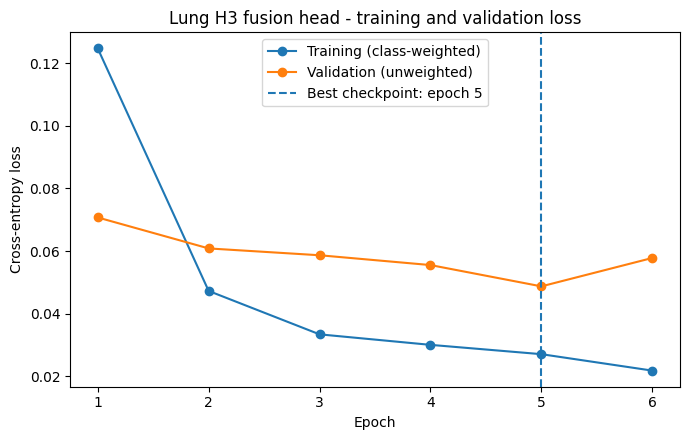

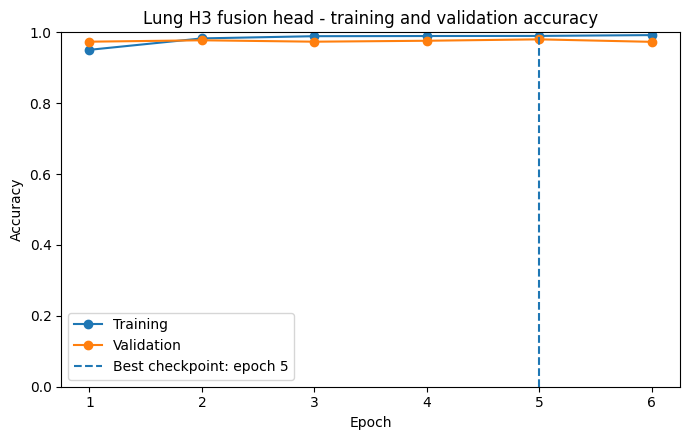

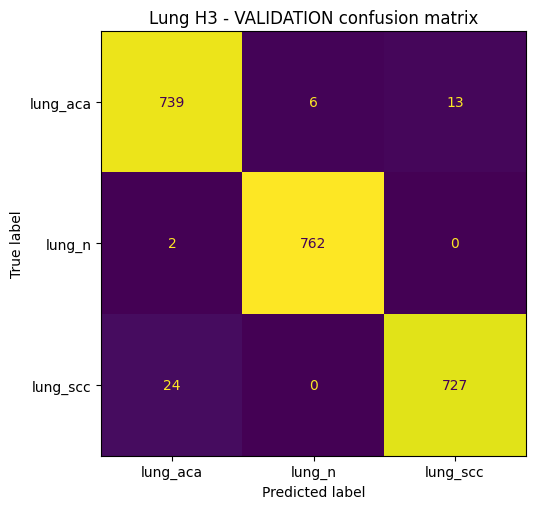

Validation-only H1 / H2 / H3 comparison:


,experiment,backbones,evaluation_split,n_images,accuracy,macro_f1,source
0,H1_MobileNetV2_frozen_seed42,MobileNetV2,validation,2273,0.970963,0.970826,H1 saved validation_metrics.json
1,H2_EfficientNetB0_frozen_seed42,EfficientNetB0,validation,2273,0.972283,0.972158,H2 saved validation_metrics.json
2,H3_MobileNetV2_EfficientNetB0_fusion_seed42,MobileNetV2 + EfficientNetB0 (pooled-feature c...,validation,2273,0.980202,0.980139,H3 saved best-head validation


,file,KiB
0,H3_MobileNetV2_EfficientNetB0_fusion_seed42_ev...,24729.6
1,RUN_SUMMARY.md,2.4
2,artifact_checksums.json,2.7
3,best_head.keras,110.3
4,class_mapping.json,0.0
5,comparison_h1_h2_h3_validation.csv,0.5
6,configuration.json,3.9
7,data_checks.json,0.7
8,environment.json,0.5
9,evaluation_environment.json,0.5


H3 validation accuracy: 98.0202%
H3 validation macro-F1: 0.9801
Saved result folder: /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H3_MobileNetV2_EfficientNetB0_fusion_seed42
Held-out test: not evaluated.


In [ ]:
# Verify full-image inference reconstruction; save H3 figures, comparisons, evidence archive.
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import zipfile

if sha256_file(RUN_DIR / 'best_head.keras') != validation_metrics['checkpoint_sha256']:
    raise ValueError('H3 saved head changed after validation.')
for code, digest in REFERENCE_CHECKPOINT_SHA256.items():
    if sha256_file(BASELINE_DIRS[code] / 'best_model.keras') != digest:
        raise ValueError(f'{code} backbone checkpoint changed before image-model export.')

# Construct a genuine end-to-end IMAGE -> pooled features -> CONCAT -> fused head pipeline.
image_input = keras.Input(shape=(*IMAGE_SIZE, 3), dtype='float32', name='rgb_0_255')
f_h1 = h1_extractor(image_input, training=False)
f_h2 = h2_extractor(image_input, training=False)
fused = keras.layers.Concatenate(name='feature_concatenation')([f_h1, f_h2])
class_scores = best_head(fused, training=False)
image_model = keras.Model(image_input, class_scores, name='H3_Deep_Feature_Fusion_Image_Model')
if h1_extractor.trainable_weights or h2_extractor.trainable_weights:
    raise RuntimeError('Reference feature extractors unexpectedly became trainable.')

# Verify composite predictions against the head evaluated on the matching cached vectors.
validation_batch, _ = next(iter(make_dataset(val_df.head(BATCH_SIZE), training=False)))
full_scores = image_model(validation_batch, training=False).numpy()
head_scores = best_head(val_features[:len(full_scores)], training=False).numpy()
np.testing.assert_allclose(full_scores, head_scores, rtol=2e-4, atol=2e-4)
full_model_path = RUN_DIR / 'fusion_image_model.keras'
image_model.save(full_model_path)
loaded_image_model = keras.models.load_model(full_model_path, compile=False)
np.testing.assert_allclose(loaded_image_model(validation_batch, training=False).numpy(),
                           head_scores, rtol=2e-4, atol=2e-4)
model_info = []
image_model.summary(print_fn=lambda line, **kwargs: model_info.append(line))
(RUN_DIR / 'fusion_image_model_summary.txt').write_text('\n'.join(model_info), encoding='utf-8')
print('Full image-input fusion model exported and save/load checked (validation batch).')

# Epoch curves are head-only fitting curves; the ImageNet backbones were frozen.
epoch_numbers = history_df['epoch'].to_numpy(dtype=int) + 1
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epoch_numbers, history_df['loss'], marker='o', label='Training (class-weighted)')
ax.plot(epoch_numbers, history_df['val_loss'], marker='o', label='Validation (unweighted)')
ax.axvline(best_epoch, linestyle='--', label=f'Best checkpoint: epoch {best_epoch}')
ax.set(xlabel='Epoch', ylabel='Cross-entropy loss',
       title='Lung H3 fusion head - training and validation loss')
ax.set_xticks(epoch_numbers)
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'training_loss.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epoch_numbers, history_df['accuracy'], marker='o', label='Training')
ax.plot(epoch_numbers, history_df['val_accuracy'], marker='o', label='Validation')
ax.axvline(best_epoch, linestyle='--', label=f'Best checkpoint: epoch {best_epoch}')
ax.set(xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1),
       title='Lung H3 fusion head - training and validation accuracy')
ax.set_xticks(epoch_numbers)
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'training_accuracy.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(6.5, 5.2))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    ax=ax, values_format='d', colorbar=False)
ax.set_title('Lung H3 - VALIDATION confusion matrix')
fig.tight_layout()
fig.savefig(RUN_DIR / 'validation_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

reference_rows = []
for code in ['H1', 'H2']:
    record = BASELINE_RECORDS[code]
    metrics, cfg = record['metrics'], record['config']
    if cfg['source_sha256']['manifest'] != CONFIG['source_sha256']['manifest']:
        raise ValueError(f'{code} source split differs; model comparison cannot be made.')
    if cfg['class_to_id'] != CONFIG['class_to_id']:
        raise ValueError(f'{code} class order differs.')
    if metrics['evaluation_split'] != 'validation' or int(metrics['n_images']) != len(val_df):
        raise ValueError(f'{code} reference metric is not compatible validation evidence.')
    reference_rows.append({
        'experiment': BASELINE_DIRS[code].name,
        'backbones': 'MobileNetV2' if code == 'H1' else 'EfficientNetB0',
        'evaluation_split': 'validation', 'n_images': len(val_df),
        'accuracy': float(metrics['accuracy']), 'macro_f1': float(metrics['macro_f1']),
        'source': f'{code} saved validation_metrics.json',
    })
comparison = pd.DataFrame(reference_rows + [{
    'experiment': RUN_NAME, 'backbones': 'MobileNetV2 + EfficientNetB0 (pooled-feature concatenation)',
    'evaluation_split': 'validation', 'n_images': len(val_df),
    'accuracy': validation_metrics['accuracy'], 'macro_f1': validation_metrics['macro_f1'],
    'source': 'H3 saved best-head validation',
}])
comparison.to_csv(RUN_DIR / 'comparison_h1_h2_h3_validation.csv', index=False)
print('Validation-only H1 / H2 / H3 comparison:')
display(comparison)

summary = f"""# {RUN_NAME} - measured experiment summary

## Study scope
Pooled feature-level fusion of the *frozen* ImageNet MobileNetV2 and EfficientNetB0
backbones saved as H1/H2 checkpoints. Their trained classification heads were NOT
averaged or fused. H1 produces 1,280 features; H2 produces 1,280 features;
concatenation creates 2,560 features. New H3 head: Dropout(0.2) -> Dense(3, softmax).

## Dataset and split
Original LC25000 lung-only source-image manifest: {CONFIG['source_sha256']['manifest']}.
Train: {len(train_df):,}; validation: {len(val_df):,}; held-out test: {EXPECTED_IMAGES['test']:,} (untouched).
Groups are *reconstructed source-image groups*, NOT patient/slide/hospital identifiers.
Pixel decode/resize uses float32 RGB [0,255] with resize-with-pad; both saved
backbones retain their respective internal scaling. Cache keyed to source/checkpoint hashes.

## Training protocol
Head-only learning with seed {SEED}, batch size {BATCH_SIZE}, Adam {LEARNING_RATE},
training class weights {class_weights}, maximum {MAX_EPOCHS} epochs,
early stopping patience {PATIENCE}, and best checkpoint by minimum validation loss.
Epochs completed: {len(history_df)}; selected best epoch: {best_epoch} (one-based).

## Measured validation performance (not test)
- Validation loss: {validation_metrics['validation_loss']:.6f}
- Accuracy: {validation_metrics['accuracy']:.6f}
- Macro-F1: {validation_metrics['macro_f1']:.6f}
- Weighted-F1: {validation_metrics['weighted_f1']:.6f}
- Correct: {validation_metrics['correct_predictions']} / {len(val_df)}

## Limits
Feature fusion does not guarantee improved accuracy, and these experiments do not
prove clinical utility or external-site generalization. Source-group separation
reduces augmented-derivative leakage but is not patient-level separation.
No stain normalization, stain-aware augmentation, Grad-CAM, robustness analysis,
external validation, or held-out test evaluation was done in this notebook.
Softmax scores are not calibrated clinical probabilities.

## Reproducibility
Best H3 head checkpoint SHA-256: {validation_metrics['checkpoint_sha256']}
H1 baseline checkpoint SHA-256: {REFERENCE_CHECKPOINT_SHA256['H1']}
H2 baseline checkpoint SHA-256: {REFERENCE_CHECKPOINT_SHA256['H2']}
Image-input composite H3 model SHA-256: {sha256_file(full_model_path)}
Feature-cache key: {FEATURE_CACHE_KEY}
Configuration fingerprint: {CONFIG_FINGERPRINT}
The executed notebook is saved separately from this evidence ZIP.
"""
(RUN_DIR / 'RUN_SUMMARY.md').write_text(summary, encoding='utf-8')
required_files = [
    'best_head.keras', 'fusion_image_model.keras', 'fusion_image_model_summary.txt',
    'model_head_summary.txt', 'configuration.json', 'environment.json', 'class_mapping.json',
    'data_checks.json', 'training_status.json', 'training_history.csv',
    'feature_cache_metadata.json', 'train_manifest_order.csv', 'val_manifest_order.csv',
    'validation_metrics.json', 'validation_predictions.csv',
    'validation_classification_report.txt', 'validation_classification_report.csv',
    'validation_confusion_matrix.csv', 'validation_confusion_matrix.png',
    'training_loss.png', 'training_accuracy.png',
    'comparison_h1_h2_h3_validation.csv', 'evaluation_environment.json', 'RUN_SUMMARY.md',
]
for name in required_files:
    path = RUN_DIR / name
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'Missing required artifact: {path}')

evidence_name = RUN_NAME + '_evidence.zip'
artifact_paths = sorted(path for path in RUN_DIR.rglob('*') if path.is_file()
                        and path.name not in {'artifact_checksums.json', evidence_name}
                        and not path.name.endswith('.tmp'))
checksums = {str(path.relative_to(RUN_DIR)): sha256_file(path) for path in artifact_paths}
save_json(RUN_DIR / 'artifact_checksums.json', checksums)
local_zip = LOCAL_ROOT / evidence_name
with zipfile.ZipFile(local_zip, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in artifact_paths + [RUN_DIR / 'artifact_checksums.json']:
        archive.write(path, arcname=str(Path(RUN_NAME) / path.relative_to(RUN_DIR)))
with zipfile.ZipFile(local_zip) as archive:
    if archive.testzip() is not None:
        raise IOError('H3 evidence ZIP failed CRC verification.')
shutil.copy2(local_zip, RUN_DIR / evidence_name)
if sha256_file(local_zip) != sha256_file(RUN_DIR / evidence_name):
    raise IOError('Evidence ZIP was not copied intact to Google Drive.')
display(pd.DataFrame([
    {'file': str(path.relative_to(RUN_DIR)), 'KiB': round(path.stat().st_size / 1024, 1)}
    for path in sorted(RUN_DIR.rglob('*')) if path.is_file()
]))
print('H3 validation accuracy:', f'{validation_metrics["accuracy"]:.4%}')
print('H3 validation macro-F1:', f'{validation_metrics["macro_f1"]:.4f}')
print('Saved result folder:', RUN_DIR)
print('Held-out test: not evaluated.')


## Reproducing the result and evaluating an already completed run

Save the **executed** notebook with outputs in Drive after completion. A fresh GPU runtime requires Sections 1–5 to reconnect/check the original source files and extracted training/validation images. Set `MODE = 'evaluate_saved'` in Section 3 before running. Section 6 then verifies the original fingerprinted feature cache; Section 7 checks the saved configuration; Section 8 **skips training**; Section 9 restores and evaluates `best_head.keras`; Section 10 validates/re-exports the image-input fusion model and supporting figures. Never rerun a completed `train_new` experiment merely to reproduce the result; its result directory is overwrite-protected.

The fusion image model and original H1/H2 checkpoints should be retained even if the training-feature cache is later archived separately. No test-data inference is part of this notebook. The first final held-out test for the selected pipeline must be separately approved, predeclared, and performed only after model selection using validation.


## Source records and scope

- `PROJECT_HANDOFF_2026-10-19_POST_U2.md` — data/split and U1/U2/H1 handoff; H2 measured results were supplied in this project's subsequent run.
- `02_Lung_MobileNetV2_Baseline.ipynb` — H1 implementation and saved H1 evidence in Google Drive.
- `04_Lung_EfficientNetB0_Baseline.ipynb` — H2 implementation and saved H2 evidence in Google Drive.
- `Histopathology Lung Cancer Project Proposal Sajjad.pdf` — approved stain-robust explainable feature-fusion plan; stain normalization, stain-aware augmentation, and Grad-CAM remain separate experiments.
- Original LC25000 lung-only archive, original group annotations, saved manifest, class mapping, and the October 16 audit.

These results are experimental image classification metrics, not patient-level diagnosis or independent hospital validation.
